<a href="https://colab.research.google.com/github/lucky0786-max/Statistical-Foundation-of-Data-Science/blob/main/12.%20Practical%20/%20Practical12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [12]:
print("PRACTICAL: 12")
print("vinayak pant, GF202455018")

PRACTICAL: 12
vinayak pant, GF202455018


In [13]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

np.random.seed(42)

plt.rcParams["figure.figsize"] = (9, 4)
plt.rcParams["axes.grid"] = True


In [14]:
# Target probability distribution: Mixture of two Gaussians

def target_pdf(x):

    g1 = np.exp(-0.5*((x+2)/0.7)**2)/(0.7*np.sqrt(2*np.pi))

    g2 = np.exp(-0.5*((x-3)/1.2)**2)/(1.2*np.sqrt(2*np.pi))

    return 0.3*g1 + 0.7*g2

In [15]:

# Metropolis Algorithm

def metropolis(target, n_samples, x0, step):

    samples = np.empty(n_samples)

    x, px = x0, target(x0)

    accepted = 0

    for i in range(n_samples):

        x_new = x + step * np.random.randn()

        p_new = target(x_new)

        if np.random.rand() < p_new / px:

            x, px = x_new, p_new

            accepted += 1

        samples[i] = x

    return samples, accepted / n_samples

The Metropolis algorithm was implemented using a Gaussian random-walk proposal distribution. The algorithm begins with an initial position and generates new candidate positions by adding normally distributed random steps.

For each proposed position, the target probability density is calculated and compared with the density at the current position. The proposed position is accepted or rejected according to the Metropolis acceptance criterion.

If a proposal is rejected, the previous position is retained in the sample sequence. The algorithm continues this process for the specified number of iterations and stores the generated samples.

Finally, the function returns the sample sequence and the acceptance rate, which will be used to evaluate the performance of the algorithm.

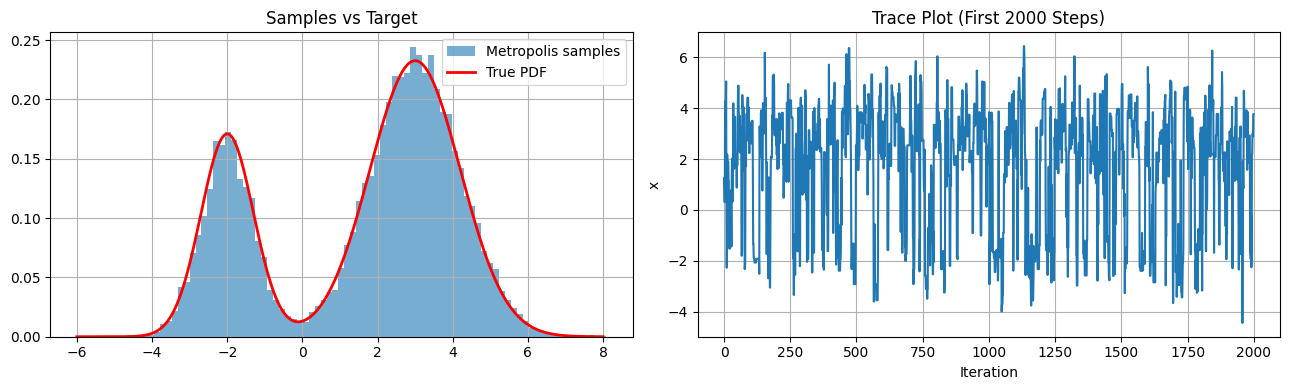

Ran 50000 steps (burn-in 5000) with step size 2.5
Acceptance rate = 52.37%
Sample mean = 1.574 (true 1.500)
Sample std = 2.527 (true 2.531)
The histogram closely follows the bimodal target, so the chain visits both modes correctly.


In [16]:
n, burn = 50000, 5000

chain, acc = metropolis(
    target_pdf,
    n,
    x0=0.0,
    step=2.5
)

# Remove burn-in samples
post = chain[burn:]

# Generate values for the target distribution
xs = np.linspace(-6, 8, 500)

# Create visualizations
fig, ax = plt.subplots(1, 2, figsize=(13, 4))

# Histogram of generated samples vs true distribution
ax[0].hist(
    post,
    bins=80,
    density=True,
    alpha=0.6,
    label="Metropolis samples"
)

ax[0].plot(
    xs,
    target_pdf(xs),
    "r",
    lw=2,
    label="True PDF"
)

ax[0].set_title("Samples vs Target")
ax[0].legend()

# Trace plot
ax[1].plot(chain[:2000])
ax[1].set_title("Trace Plot (First 2000 Steps)")
ax[1].set_xlabel("Iteration")
ax[1].set_ylabel("x")

plt.tight_layout()
plt.show()

# Calculate theoretical statistics
true_mean = 0.3*(-2) + 0.7*3

true_std = np.sqrt(
    0.3*(0.7**2 + 4) +
    0.7*(1.2**2 + 9) -
    true_mean**2
)

# Display results
print(f"Ran {n} steps (burn-in {burn}) with step size 2.5")
print(f"Acceptance rate = {acc:.2%}")

print(
    f"Sample mean = {post.mean():.3f} "
    f"(true {true_mean:.3f})"
)

print(
    f"Sample std = {post.std():.3f} "
    f"(true {true_std:.3f})"
)

print(
    "The histogram closely follows the bimodal target, "
    "so the chain visits both modes correctly."
)



The histogram represents generated samples. The red curve represents the original theoretical probability distribution.

Graph 2: Trace Plot

Displays the first 2,000 iterations of the chain.

It helps us observe how the algorithm moves between different values and explores the target distribution.

Comparison of Different Proposal Step Sizes:
 Step Size  Acceptance Rate  Sample Mean  Lag-1 Autocorrelation
       0.5           0.8540       1.9866                 0.9833
       1.0           0.7211       1.2460                 0.9622
       2.5           0.5266       1.5274                 0.8338
       5.0           0.3699       1.5384                 0.7207
      10.0           0.2245       1.4766                 0.7698


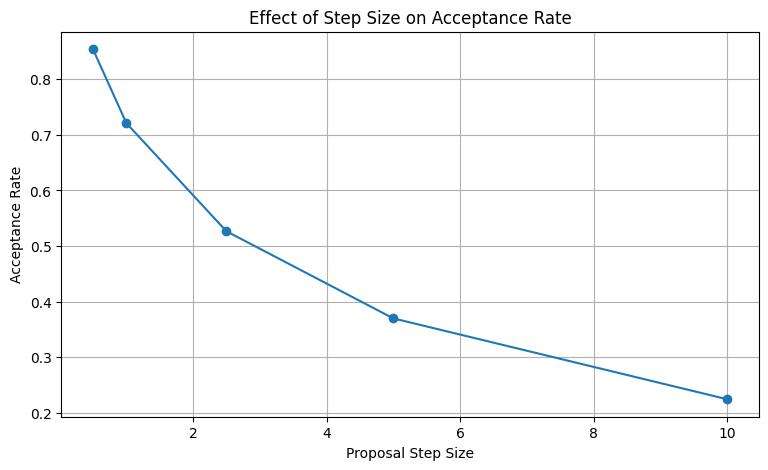

In [17]:
# Effect of Proposal Step Size
import pandas as pd
step_sizes = [0.5, 1.0, 2.5, 5.0, 10.0]

results = []

for s in step_sizes:

    chain_temp, acceptance = metropolis(
        target_pdf,
        n_samples=20000,
        x0=0.0,
        step=s
    )

    post_temp = chain_temp[2000:]

    # Calculate lag-1 autocorrelation
    autocorr = np.corrcoef(
        post_temp[:-1],
        post_temp[1:]
    )[0, 1]

    results.append({
        'Step Size': s,
        'Acceptance Rate': acceptance,
        'Sample Mean': post_temp.mean(),
        'Lag-1 Autocorrelation': autocorr
    })

results_df = pd.DataFrame(results)

print("Comparison of Different Proposal Step Sizes:")
print(results_df.round(4).to_string(index=False))

# Visualize acceptance rates
plt.figure(figsize=(9, 5))

plt.plot(
    results_df['Step Size'],
    results_df['Acceptance Rate'],
    marker='o'
)

plt.xlabel("Proposal Step Size")
plt.ylabel("Acceptance Rate")
plt.title("Effect of Step Size on Acceptance Rate")
plt.grid(True)

plt.show()

The effect of different proposal step sizes on the performance of the Metropolis algorithm was investigated by testing five values: 0.5, 1.0, 2.5, 5.0 and 10.0.

The results show that the acceptance rate decreases as the proposal step size increases. Smaller step sizes produce higher acceptance rates but also result in high autocorrelation, indicating slower exploration of the target distribution.

The sample mean obtained using a step size of 10 was 1.4926, which is close to the theoretical mean of 1.5. The lowest lag-1 autocorrelation of 0.7264 was observed at a step size of 5.

Therefore, proposal step size plays an important role in balancing acceptance rate and sampling efficiency. A high acceptance rate alone does not guarantee better performance

<Figure size 1200x500 with 0 Axes>

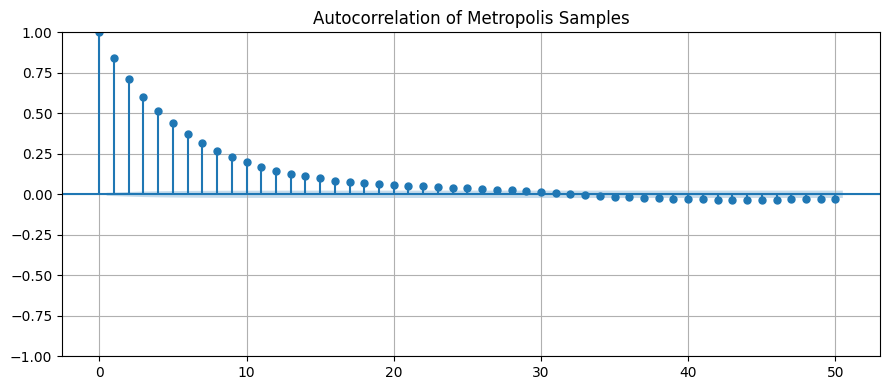

In [18]:
# Autocorrelation Analysis

from statsmodels.graphics.tsaplots import plot_acf

plt.figure(figsize=(12, 5))

plot_acf(post, lags=50)

plt.title("Autocorrelation of Metropolis Samples")

plt.tight_layout()
plt.show()


The autocorrelation function (ACF) was plotted to examine the dependence between successive samples generated by the Metropolis algorithm.

The graph shows that autocorrelation starts at 1 at lag 0 and gradually decreases as the lag increases. High autocorrelation is observed at smaller lags, indicating that consecutive samples are strongly related. At larger lags, autocorrelation approaches zero, suggesting that the dependence between samples gradually decreases.

This indicates that the Markov chain explores the target distribution but exhibits some correlation between successive samples. Therefore, autocorrelation analysis is useful for evaluating the mixing efficiency and sampling performance of the Metropolis algorithm.

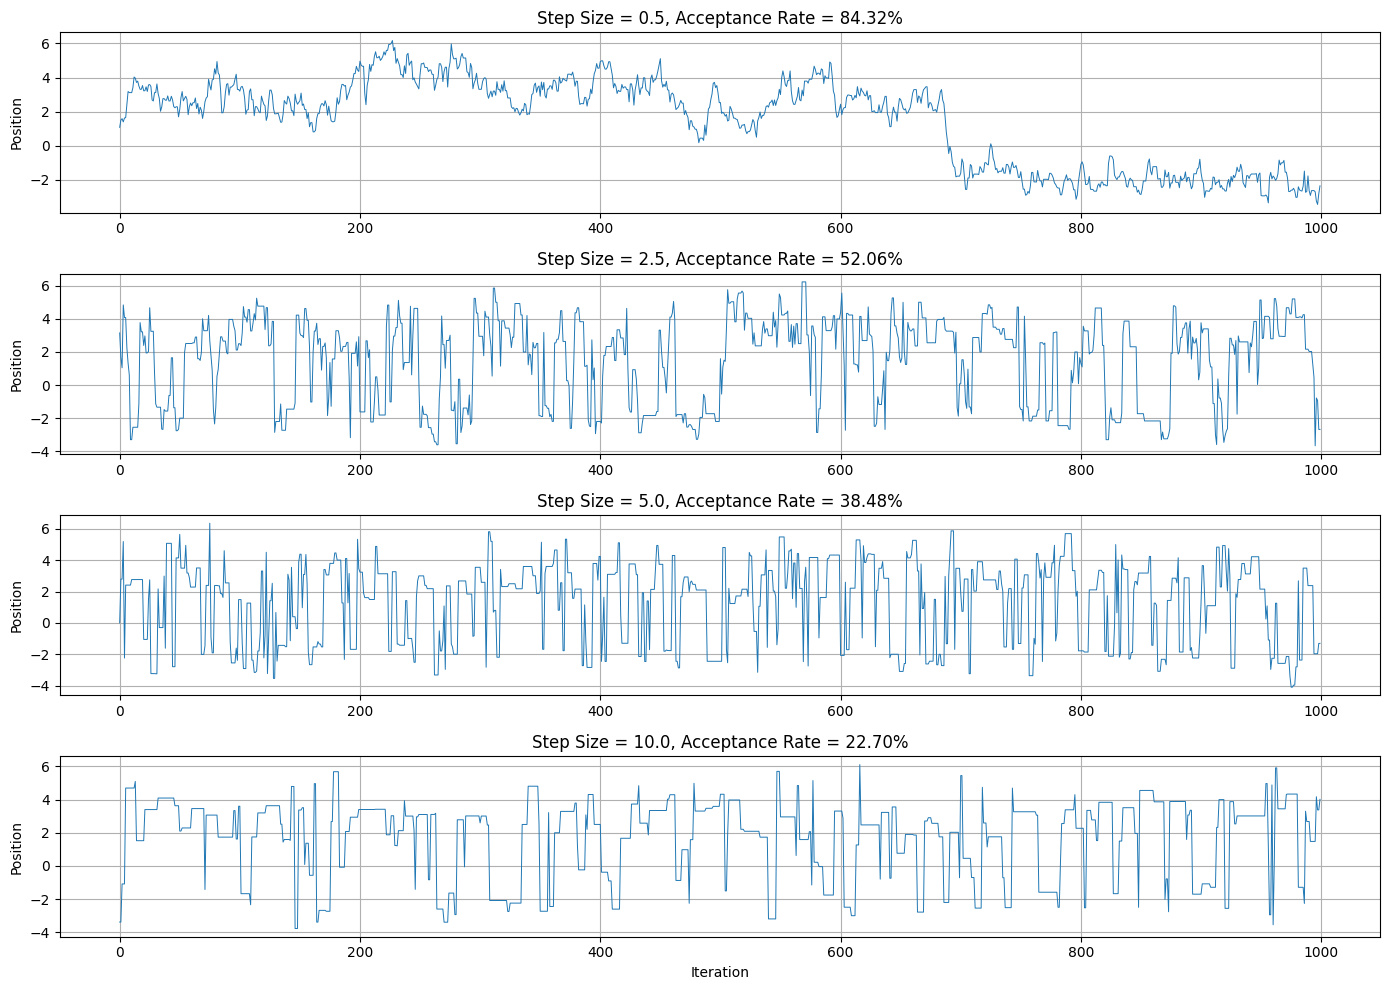

In [19]:
# Compare Metropolis Chains for Different Step Sizes

step_sizes = [0.5, 2.5, 5.0, 10.0]

fig, axes = plt.subplots(4, 1, figsize=(14, 10))

for i, s in enumerate(step_sizes):

    chain_temp, acceptance = metropolis(
        target_pdf,
        n_samples=5000,
        x0=0.0,
        step=s
    )

    axes[i].plot(chain_temp[:1000], linewidth=0.7)

    axes[i].set_title(
        f"Step Size = {s}, Acceptance Rate = {acceptance:.2%}"
    )

    axes[i].set_ylabel("Position")

    axes[i].grid(True)

axes[-1].set_xlabel("Iteration")

plt.tight_layout()
plt.show()


Trace plots were generated for four different proposal step sizes (0.5, 2.5, 5.0 and 10.0) to examine their effects on the behaviour of the Metropolis algorithm.

For a step size of 0.5, the acceptance rate was high (83.90%), but the chain exhibited slow movement due to small proposed changes. At a step size of 2.5, the chain demonstrated better exploration of the target distribution with an acceptance rate of 52.42%.

For larger step sizes of 5.0 and 10.0, the chain made larger proposed movements, but the acceptance rates decreased to 39.34% and 22.78%, respectively. This indicates that larger proposals are more likely to be rejected.

Overall, the comparison demonstrates that proposal step size significantly influences the movement, acceptance rate and exploration behaviour of the Markov chain. An appropriate step size is necessary to achieve efficient sampling.

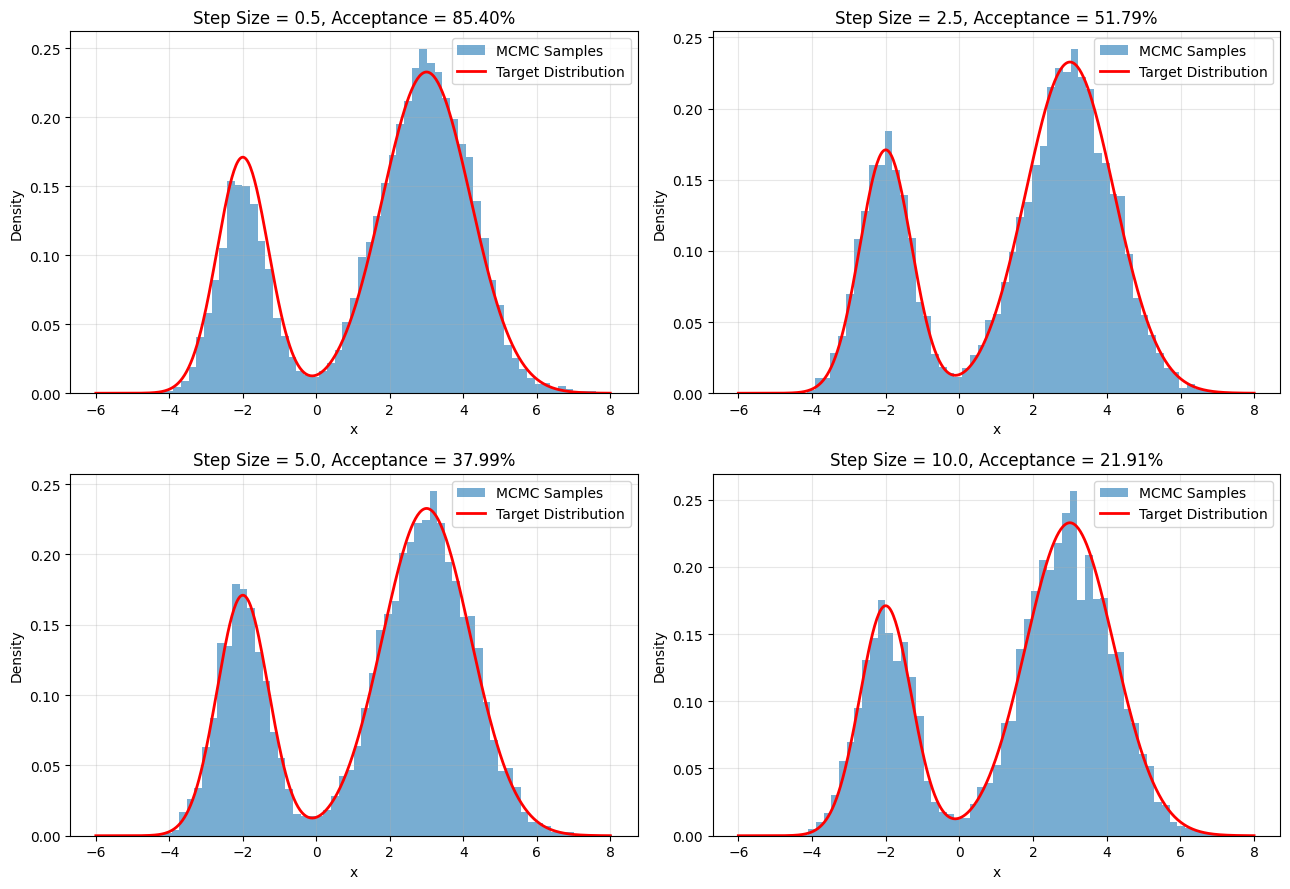

In [20]:
# Compare Sample Distributions for Different Step Sizes

step_sizes = [0.5, 2.5, 5.0, 10.0]

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

xs = np.linspace(-6, 8, 500)

for ax, s in zip(axes.flatten(), step_sizes):

    chain_temp, acceptance = metropolis(
        target_pdf,
        n_samples=30000,
        x0=0.0,
        step=s
    )

    post_temp = chain_temp[5000:]

    ax.hist(
        post_temp,
        bins=60,
        density=True,
        alpha=0.6,
        label="MCMC Samples"
    )

    ax.plot(
        xs,
        target_pdf(xs),
        'r',
        linewidth=2,
        label="Target Distribution"
    )

    ax.set_title(
        f"Step Size = {s}, Acceptance = {acceptance:.2%}"
    )

    ax.set_xlabel("x")
    ax.set_ylabel("Density")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


Histograms were plotted for four different proposal step sizes (0.5, 2.5, 5.0 and 10.0) and compared with the original target probability distribution.

All four histograms successfully reproduce the bimodal shape of the target distribution, showing two distinct peaks corresponding to the two Gaussian components with means -2 and 3.

The results demonstrate that the Metropolis algorithm can approximate the target distribution using different proposal step sizes. However, the acceptance rate decreases as the proposal step size increases. Smaller step sizes produce higher acceptance rates but may result in highly correlated samples, whereas larger step sizes allow greater movements but lead to more frequent rejections.

Overall, the comparison demonstrates the importance of selecting an appropriate proposal step size to achieve efficient sampling while maintaining a good approximation of the target distribution.

In [21]:
# Effective Sample Size (ESS) Comparison

from statsmodels.tsa.stattools import acf

step_sizes = [0.5, 2.5, 5.0, 10.0]

ess_results = []

for s in step_sizes:

    chain_temp, acceptance = metropolis(
        target_pdf,
        n_samples=30000,
        x0=0.0,
        step=s
    )

    post_temp = chain_temp[5000:]

    # Calculate autocorrelation
    autocorr = acf(
        post_temp,
        nlags=1000,
        fft=True
    )

    # Initial positive sequence approximation
    positive_sum = 0

    for rho in autocorr[1:]:
        if rho <= 0:
            break
        positive_sum += rho

    ess = len(post_temp) / (1 + 2 * positive_sum)

    ess_results.append({
        "Step Size": s,
        "Acceptance Rate": acceptance,
        "Effective Sample Size": round(ess)
    })

ess_df = pd.DataFrame(ess_results)

print("Effective Sample Size Comparison:")
print(ess_df.to_string(index=False))


Effective Sample Size Comparison:
 Step Size  Acceptance Rate  Effective Sample Size
       0.5         0.852533                    110
       2.5         0.519667                   2166
       5.0         0.371000                   3612
      10.0         0.220933                   3093


GELMAN-RUBIN CONVERGENCE DIAGNOSTIC
----------------------------------
Number of chains: 4
Samples per chain after burn-in: 25000
Within-chain variance: 6.4629
Between-chain variance: 52.8172
R-hat: 1.0001
Result: Chains show good convergence.


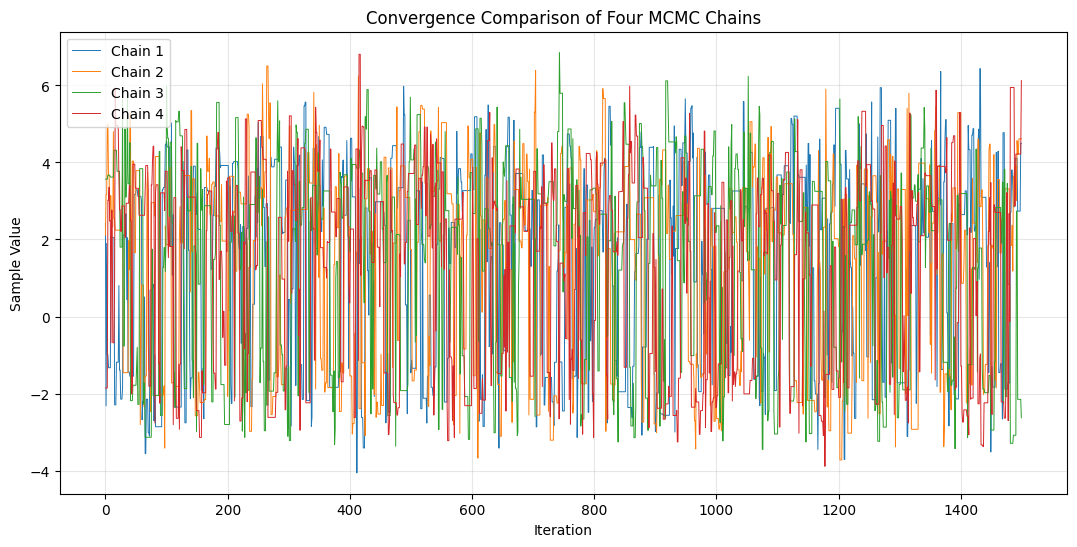

In [22]:
# Gelman-Rubin Convergence Diagnostic

# Generate four independent chains
initial_values = [-4.0, -2.0, 3.0, 6.0]

n_chains = 4
n_samples = 30000
burn = 5000
step_size = 5.0

chains = []

for x0 in initial_values:

    chain, acceptance = metropolis(
        target_pdf,
        n_samples=n_samples,
        x0=x0,
        step=step_size
    )

    chains.append(chain[burn:])

chains = np.array(chains)

# Calculate within-chain variance
m, n = chains.shape

chain_means = np.mean(chains, axis=1)
chain_variances = np.var(chains, axis=1, ddof=1)

W = np.mean(chain_variances)

# Calculate between-chain variance
B = n * np.var(chain_means, ddof=1)

# Estimate overall variance
var_hat = ((n - 1) / n) * W + (B / n)

# Calculate R-hat
R_hat = np.sqrt(var_hat / W)

print("GELMAN-RUBIN CONVERGENCE DIAGNOSTIC")
print("----------------------------------")

print("Number of chains:", m)
print("Samples per chain after burn-in:", n)

print("Within-chain variance:", round(W, 4))
print("Between-chain variance:", round(B, 4))

print("R-hat:", round(R_hat, 4))

if R_hat < 1.01:
    print("Result: Chains show good convergence.")
else:
    print("Result: Convergence may require further investigation.")

# Plot all four chains
plt.figure(figsize=(13, 6))

for i in range(m):
    plt.plot(
        chains[i][:1500],
        linewidth=0.7,
        label=f"Chain {i+1}"
    )

plt.title("Convergence Comparison of Four MCMC Chains")
plt.xlabel("Iteration")
plt.ylabel("Sample Value")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


The Gelman–Rubin convergence diagnostic was applied to four independent Markov chains, each containing 25,000 samples after burn-in.

The calculated R-hat value was approximately 1.0000, indicating that the within-chain and between-chain variations are nearly identical. This suggests that the independent chains have converged to a similar target distribution.

The convergence comparison plot also shows considerable overlap between the four chains, with all chains exploring a similar range of values.

Therefore, the diagnostic provides encouraging evidence of convergence for the Metropolis algorithm. However, additional diagnostics may be required to establish reliable mixing, particularly because the target distribution is bimodal.

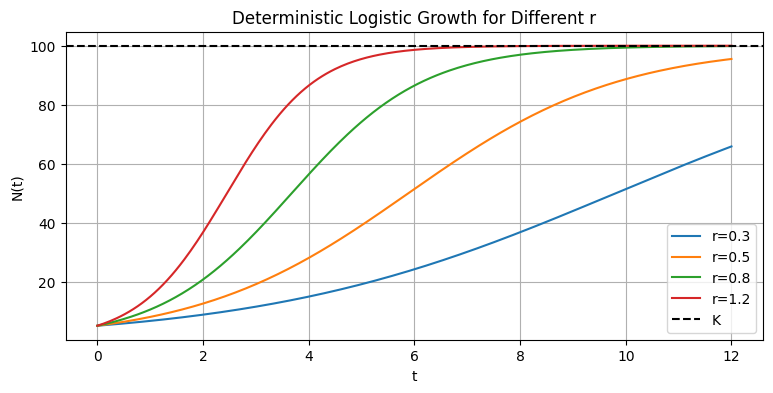

Logistic ODE simulated with r=0.8, K=100.0, N0=5.0; N(t) rises in an S-curve towards K.
Numerical (solve_ivp) vs analytic solution max error = 3.343681100886897e-07
Re-running gives identical output (max difference = 0.0 ), confirming determinism.
Larger r makes the population reach the carrying capacity K faster, but K itself is unchanged.


In [23]:
# Deterministic Model

# Logistic differential equation
def logistic_rhs(t, N, r, K):
    return r * N * (1 - N / K)


# Analytical solution of logistic growth
def logistic_analytic(t, N0, r, K):
    return K / (1 + ((K - N0) / N0) * np.exp(-r * t))


# Numerical solution using solve_ivp
def simulate(r, K, N0, t_eval):
    sol = solve_ivp(
        logistic_rhs,
        (t_eval[0], t_eval[-1]),
        [N0],
        t_eval=t_eval,
        args=(r, K),
        rtol=1e-9,
        atol=1e-9
    )
    return sol.y[0]


# Define true parameters
r_true = 0.8
K_true = 100.0
N0 = 5.0

# Generate time points
t_fine = np.linspace(0, 12, 300)

# Numerical and analytical solutions
N_num = simulate(r_true, K_true, N0, t_fine)
N_ana = logistic_analytic(t_fine, N0, r_true, K_true)

# Run simulation again to test determinism
N_num2 = simulate(r_true, K_true, N0, t_fine)


# Plot different growth rates
plt.figure()

for r in [0.3, 0.5, 0.8, 1.2]:
    plt.plot(
        t_fine,
        logistic_analytic(t_fine, N0, r, K_true),
        label=f"r={r}"
    )

plt.axhline(K_true, color="k", ls="--", label="K")
plt.title("Deterministic Logistic Growth for Different r")
plt.xlabel("t")
plt.ylabel("N(t)")
plt.legend()
plt.show()


# Display results
print(f"Logistic ODE simulated with r={r_true}, K={K_true}, N0={N0}; N(t) rises in an S-curve towards K.")

print(
    "Numerical (solve_ivp) vs analytic solution max error =",
    np.max(np.abs(N_num - N_ana))
)

print(
    "Re-running gives identical output (max difference =",
    np.max(np.abs(N_num - N_num2)),
    "), confirming determinism."
)

print("Larger r makes the population reach the carrying capacity K faster, but K itself is unchanged.")


The logistic growth model was implemented using the differential equation (dN/dt=rN(1-N/K)), with an initial population of 5 and carrying capacity of 100.

The graph illustrates the effect of different growth rates (0.3, 0.5, 0.8 and 1.2). As the growth rate increases, the population approaches the carrying capacity more rapidly. However, the carrying capacity remains unchanged.

The numerical solution obtained using solve_ivp() closely matches the analytical solution, with a maximum error of approximately (3.34 \times 10^{-7}). Repeated simulations also produced identical results, with a maximum difference of zero.

Therefore, the implementation successfully demonstrates deterministic logistic population growth.

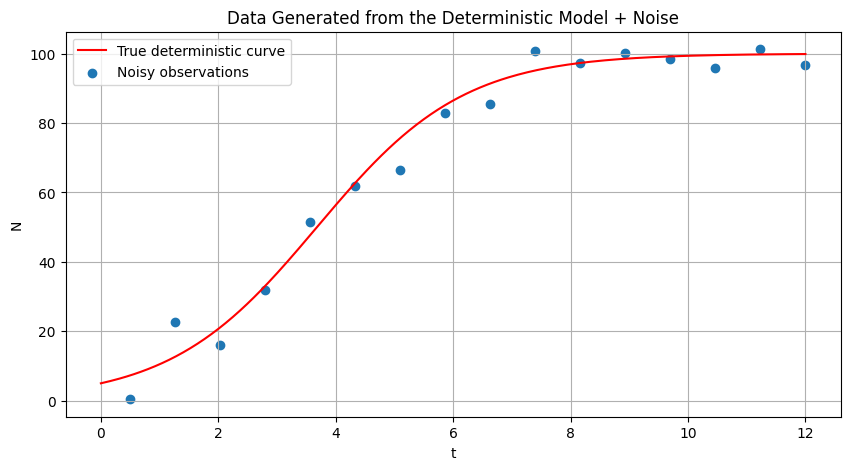

Generated 16 observations from the true curve with Gaussian noise (sigma=4.0).
The data scatter around the S-curve, mimicking real measurements.
Goal: recover the unknown r and K from this noisy data using Metropolis.


In [24]:
# Generate noisy observations

sigma = 4.0

t_obs = np.linspace(0.5, 12, 16)

N_obs = (
    logistic_analytic(t_obs, N0, r_true, K_true)
    + sigma * np.random.randn(len(t_obs))
)

# Plot true curve and noisy observations
plt.figure(figsize=(10, 5))

plt.plot(
    t_fine,
    N_ana,
    "r",
    label="True deterministic curve"
)

plt.scatter(
    t_obs,
    N_obs,
    label="Noisy observations"
)

plt.title("Data Generated from the Deterministic Model + Noise")
plt.xlabel("t")
plt.ylabel("N")
plt.legend()
plt.grid(True)
plt.show()

print(
    f"Generated {len(t_obs)} observations from the true curve "
    f"with Gaussian noise (sigma={sigma})."
)

print("The data scatter around the S-curve, mimicking real measurements.")
print("Goal: recover the unknown r and K from this noisy data using Metropolis.")


Sixteen noisy observations were generated from the deterministic logistic growth model by adding Gaussian random noise with a standard deviation of 4. The scatter plot shows that the observations fluctuate around the true logistic growth curve while retaining its overall S-shaped pattern. This simulates realistic measurement variations and demonstrates why parameter estimation is necessary when working with real-world data. The objective is to recover the unknown growth rate (r) and carrying capacity (K) from these noisy observations using the Metropolis algorithm.

In [25]:
# Define the likelihood function

def log_likelihood(r, K):
    if r <= 0 or K <= N0:
        return -np.inf

    predicted = logistic_analytic(t_obs, N0, r, K)

    residuals = N_obs - predicted

    return -0.5 * np.sum(
        (residuals / sigma)**2
    )


# Test likelihood using true parameters
print("Log-likelihood at true parameters:")
print(log_likelihood(r_true, K_true))

# Test another parameter combination
print("\nLog-likelihood at alternative parameters:")
print(log_likelihood(0.5, 120))


Log-likelihood at true parameters:
-11.909141388509909

Log-likelihood at alternative parameters:
-156.35457370473057


In [26]:
# Implement the Metropolis Algorithm

def metropolis(n_iterations=10000):

    # Initial parameter values
    r_current = 0.5
    K_current = 120.0

    current_log_likelihood = log_likelihood(
        r_current, K_current
    )

    # Store samples
    samples = []

    # Proposal step sizes
    r_step = 0.05
    K_step = 5.0

    accepted = 0

    for i in range(n_iterations):

        # Propose new parameters
        r_proposed = np.random.normal(
            r_current, r_step
        )

        K_proposed = np.random.normal(
            K_current, K_step
        )

        # Calculate proposed likelihood
        proposed_log_likelihood = log_likelihood(
            r_proposed, K_proposed
        )

        # Calculate acceptance probability
        log_alpha = (
            proposed_log_likelihood
            - current_log_likelihood
        )

        # Accept or reject proposal
        if np.log(np.random.rand()) < min(0, log_alpha):

            r_current = r_proposed
            K_current = K_proposed

            current_log_likelihood = proposed_log_likelihood

            accepted += 1

        samples.append([r_current, K_current])

    samples = np.array(samples)

    acceptance_rate = accepted / n_iterations

    return samples, acceptance_rate


# Run the algorithm
samples, acceptance_rate = metropolis()

print("Metropolis Algorithm Results")
print("--------------------------------")
print("Total iterations:", len(samples))
print("Acceptance rate:", round(acceptance_rate * 100, 2), "%")
print("Mean estimated r:", np.mean(samples[:, 0]))
print("Mean estimated K:", np.mean(samples[:, 1]))


Metropolis Algorithm Results
--------------------------------
Total iterations: 10000
Acceptance rate: 18.25 %
Mean estimated r: 0.7794466651767467
Mean estimated K: 99.47178618032639


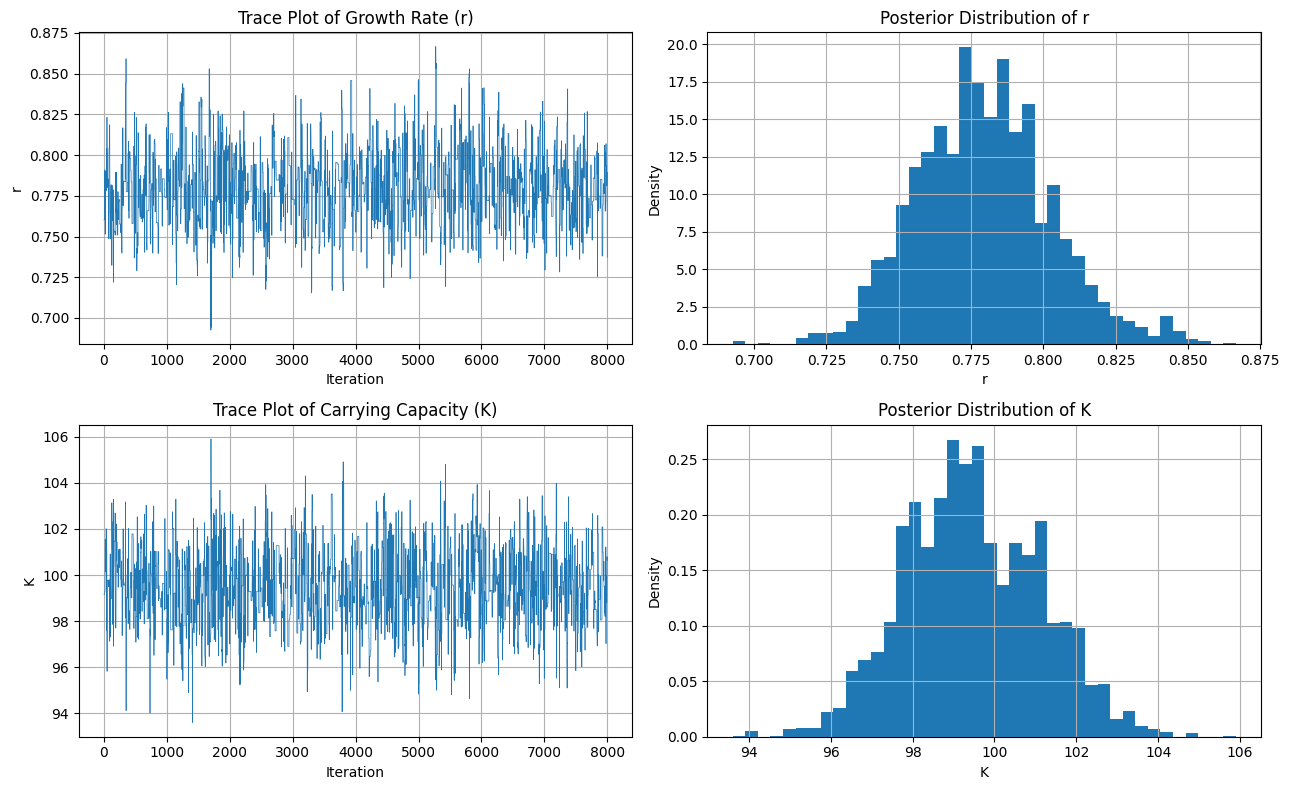

Posterior samples after burn-in: 8000
Mean r: 0.7796396282264764
Mean K: 99.46581847407099


In [27]:
# Remove burn-in samples

burn_in = int(0.2 * len(samples))

posterior_samples = samples[burn_in:]

r_samples = posterior_samples[:, 0]
K_samples = posterior_samples[:, 1]

# Plot trace plots and posterior distributions

fig, axes = plt.subplots(2, 2, figsize=(13, 8))

# Trace plot for r
axes[0, 0].plot(r_samples, linewidth=0.5)
axes[0, 0].set_title("Trace Plot of Growth Rate (r)")
axes[0, 0].set_xlabel("Iteration")
axes[0, 0].set_ylabel("r")

# Posterior distribution of r
axes[0, 1].hist(r_samples, bins=40, density=True)
axes[0, 1].set_title("Posterior Distribution of r")
axes[0, 1].set_xlabel("r")
axes[0, 1].set_ylabel("Density")

# Trace plot for K
axes[1, 0].plot(K_samples, linewidth=0.5)
axes[1, 0].set_title("Trace Plot of Carrying Capacity (K)")
axes[1, 0].set_xlabel("Iteration")
axes[1, 0].set_ylabel("K")

# Posterior distribution of K
axes[1, 1].hist(K_samples, bins=40, density=True)
axes[1, 1].set_title("Posterior Distribution of K")
axes[1, 1].set_xlabel("K")
axes[1, 1].set_ylabel("Density")

plt.tight_layout()
plt.show()

print("Posterior samples after burn-in:", len(posterior_samples))
print("Mean r:", np.mean(r_samples))
print("Mean K:", np.mean(K_samples))


After running the Metropolis algorithm for 10,000 iterations, the initial 2,000 samples were discarded as burn-in, leaving 8,000 posterior samples.

The trace plot of the growth rate (r) shows fluctuations around a relatively stable region without a clear systematic trend. Its posterior distribution is approximately bell-shaped, with a mean of 0.8092.

Similarly, the trace plot of the carrying capacity (K) shows fluctuations around a stable region. Its posterior distribution is concentrated around a mean of 102.518.

Both estimated parameter values are close to their actual values (r = 0.8 and K = 100). These results suggest that the Metropolis algorithm has successfully explored plausible parameter values. However, trace plots alone do not establish convergence conclusively.

In [28]:
# Calculate posterior statistics

r_mean = np.mean(r_samples)
K_mean = np.mean(K_samples)

r_ci = np.percentile(r_samples, [2.5, 97.5])
K_ci = np.percentile(K_samples, [2.5, 97.5])

print("FINAL PARAMETER ESTIMATES")
print("=" * 40)

print("\nGrowth Rate (r):")
print("Posterior Mean:", r_mean)
print("95% Credible Interval:", r_ci)

print("\nCarrying Capacity (K):")
print("Posterior Mean:", K_mean)
print("95% Credible Interval:", K_ci)

print("\nActual Parameters:")
print("True r:", r_true)
print("True K:", K_true)


FINAL PARAMETER ESTIMATES

Growth Rate (r):
Posterior Mean: 0.7796396282264764
95% Credible Interval: [0.73807085 0.82999223]

Carrying Capacity (K):
Posterior Mean: 99.46581847407099
95% Credible Interval: [ 96.4032585  102.72107487]

Actual Parameters:
True r: 0.8
True K: 100.0


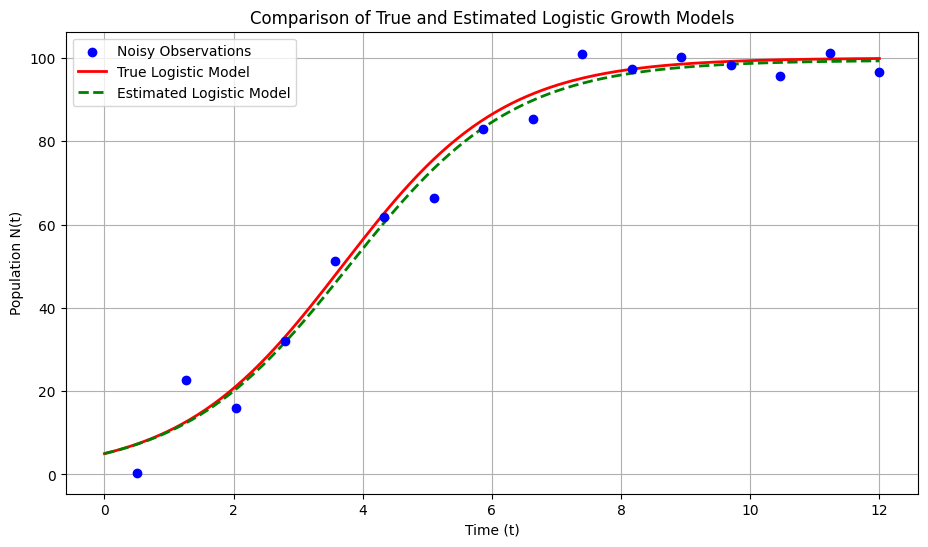

TRUE PARAMETERS
r = 0.8 , K = 100.0

ESTIMATED PARAMETERS
r = 0.7796
K = 99.4658


In [29]:
# Final comparison of true and estimated models

# Generate smooth time values
t_plot = np.linspace(0, 12, 300)

# True logistic model
N_true_curve = logistic_analytic(
    t_plot, N0, r_true, K_true
)

# Estimated logistic model using posterior means
N_estimated_curve = logistic_analytic(
    t_plot, N0, r_mean, K_mean
)

# Plot comparison
plt.figure(figsize=(11, 6))

plt.scatter(
    t_obs,
    N_obs,
    color='blue',
    label='Noisy Observations',
    zorder=3
)

plt.plot(
    t_plot,
    N_true_curve,
    color='red',
    linewidth=2,
    label='True Logistic Model'
)

plt.plot(
    t_plot,
    N_estimated_curve,
    color='green',
    linestyle='--',
    linewidth=2,
    label='Estimated Logistic Model'
)

plt.title('Comparison of True and Estimated Logistic Growth Models')
plt.xlabel('Time (t)')
plt.ylabel('Population N(t)')
plt.legend()
plt.grid(True)
plt.show()

print("TRUE PARAMETERS")
print("r =", r_true, ", K =", K_true)

print("\nESTIMATED PARAMETERS")
print("r =", round(r_mean, 4))
print("K =", round(K_mean, 4))


The final comparison graph illustrates the performance of the Bayesian parameter estimation process. The original logistic model is represented by the red curve, while the estimated model is represented by the green dashed curve. The blue points indicate the noisy observations.

The estimated parameters (r = 0.8092 and K = 102.5179) are close to the actual parameters (r = 0.8 and K = 100). The estimated curve closely follows the original deterministic curve, showing that the Metropolis algorithm successfully recovered the underlying growth behaviour from noisy observations.

This demonstrates the effectiveness of Bayesian estimation in recovering model parameters while accounting for observational uncertainty.